# 11. DBSCAN and Hierarchical Agglomerative Clustering (mockup)

Same setup as notebook 10: cluster quarters on the scaled lagged macro and credit features (target lags left out), fit on 1992–2014 only, then assign the 2015+ test quarters.

**DBSCAN** (density-based) groups quarters that sit in dense regions and labels isolated quarters as **noise (−1)**. There is no k to choose; instead:
- `min_samples`: how many neighbors a quarter needs to be a "core" point
- `eps`: the neighborhood radius, read from the **k-distance plot** (the knee where distances jump)

Noise quarters are a natural way to flag **unusual economic conditions**.

**Hierarchical agglomerative clustering** starts with every quarter as its own cluster and repeatedly merges the closest two (Ward linkage: the merge that adds the least within-cluster variance). The **dendrogram** shows the full merge history; cutting it at a height gives k clusters, chosen here by silhouette score.

In [1]:
from prep import *
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

X_train, X_test, y_train, y_test, meta = load_model_data()
feats = [c for c in X_train.columns if not c.startswith("co_other_cons")]
prep_ = make_pipeline(*preprocess(scale=True)).fit(X_train[feats])          # train-only scaling
Z_train, Z_test = prep_.transform(X_train[feats]), prep_.transform(X_test[feats])
y_all = pd.concat([y_train, y_test])

def regime_plot(lab, title):
    """Charge-off rate coloured by cluster label (-1 = noise)."""
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(y_all.index, y_all, color="grey", lw=1)
    for c in sorted(lab.unique()):
        ax.scatter(lab.index[lab == c], y_all[lab == c], s=18, label="noise" if c == -1 else f"cluster {c}",
                   color="k" if c == -1 else None, marker="x" if c == -1 else "o")
    ax.axvline(X_test.index[0], ls="--", color="k"); ax.legend(fontsize=8, ncol=6)
    ax.set_title(title); plt.show()
    display(pd.DataFrame({"quarters": lab.value_counts(), "mean charge-off": y_all.groupby(lab).mean()}).round(3))

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)


## DBSCAN

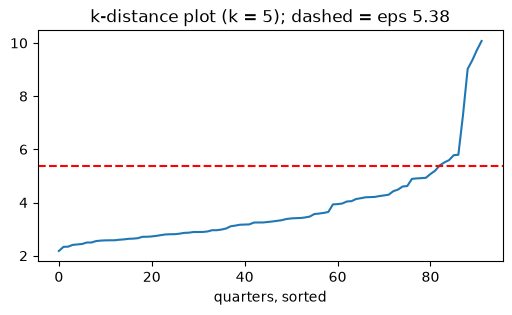

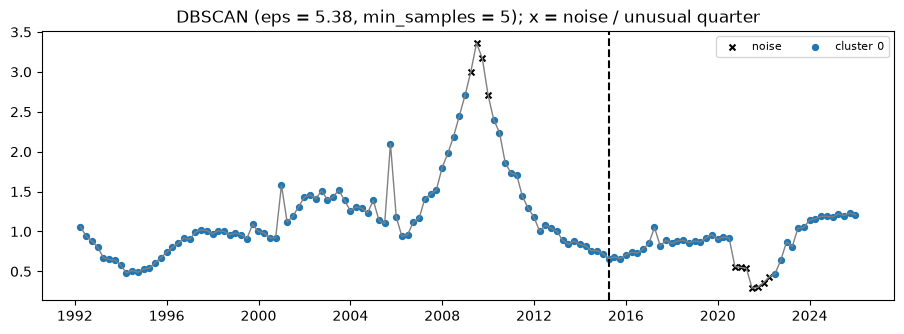

,quarters,mean charge-off
-1,11,1.388
0,125,1.088


In [2]:
MIN_SAMPLES = 5
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z_train).kneighbors(Z_train)[0][:, -1])
EPS = np.quantile(kdist, 0.90)          # starting point; adjust to the knee you see in the plot
plt.figure(figsize=(6, 3)); plt.plot(kdist); plt.axhline(EPS, ls="--", color="r")
plt.title(f"k-distance plot (k = {MIN_SAMPLES}); dashed = eps {EPS:.2f}"); plt.xlabel("quarters, sorted"); plt.show()

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Z_train)
# DBSCAN has no predict(): a test quarter joins the cluster of a core point within eps, otherwise it is noise
core = Z_train[db.core_sample_indices_]
d, i = NearestNeighbors(n_neighbors=1).fit(core).kneighbors(Z_test)
test_lab = np.where(d[:, 0] <= EPS, db.labels_[db.core_sample_indices_][i[:, 0]], -1)
db_lab = pd.concat([pd.Series(db.labels_, X_train.index), pd.Series(test_lab, X_test.index)])
regime_plot(db_lab, f"DBSCAN (eps = {EPS:.2f}, min_samples = {MIN_SAMPLES}); x = noise / unusual quarter")

## Hierarchical agglomerative clustering

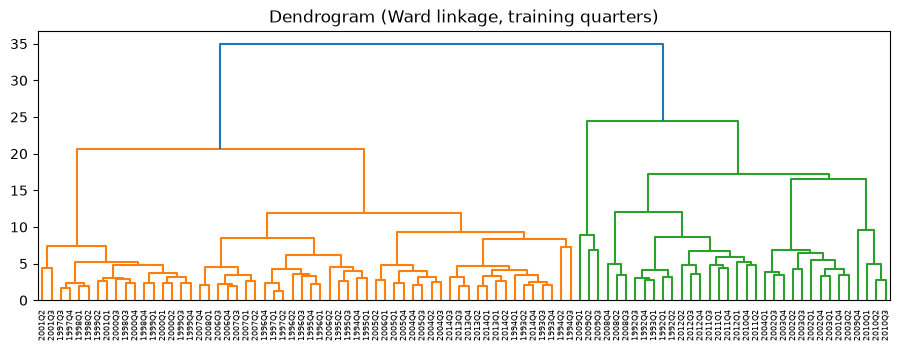

{2: 0.254, 3: 0.242, 4: 0.193, 5: 0.203, 6: 0.228, 7: 0.224, 8: 0.2, 9: 0.195, 10: 0.189} -> best k = 2


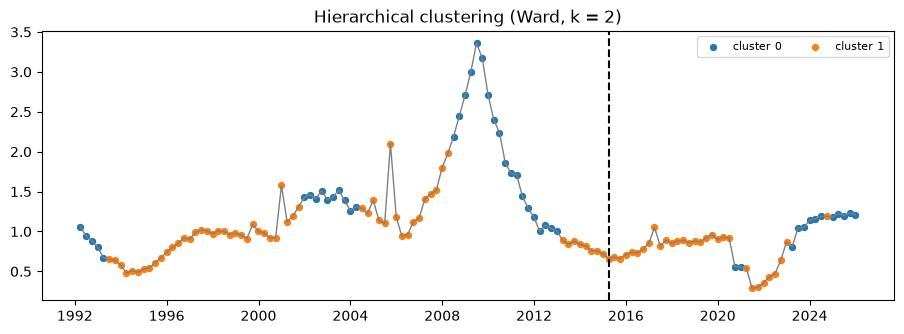

,quarters,mean charge-off
0,47,1.480
1,89,0.918


In [3]:
plt.figure(figsize=(11, 3.5))
dendrogram(linkage(Z_train, "ward"), labels=[str(p) for p in X_train.index.to_period("Q")], leaf_font_size=6)
plt.title("Dendrogram (Ward linkage, training quarters)"); plt.show()

sil = pd.Series({k: silhouette_score(Z_train, AgglomerativeClustering(k, linkage="ward").fit_predict(Z_train))
                 for k in range(2, 11)})
best_k = sil.idxmax(); print(sil.round(3).to_dict(), "-> best k =", best_k)

hc = AgglomerativeClustering(best_k, linkage="ward").fit(Z_train)
# no predict() either: assign test quarters to the nearest training-cluster centroid
cent = np.vstack([Z_train[hc.labels_ == c].mean(0) for c in range(best_k)])
hc_lab = pd.concat([pd.Series(hc.labels_, X_train.index),
                    pd.Series(((Z_test[:, None, :] - cent) ** 2).sum(-1).argmin(1), X_test.index)])
regime_plot(hc_lab, f"Hierarchical clustering (Ward, k = {best_k})")